# 🌐 Message Intelligence System

## 🧪 Part B: Dataset Understanding & Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("Message_Intelligence_Dataset_5200.csv")

In [4]:
df.head(5)

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   message_id               5200 non-null   int64  
 1   message_text             5200 non-null   object 
 2   message_length           5200 non-null   int64  
 3   word_count               5200 non-null   int64  
 4   num_urls                 5200 non-null   int64  
 5   num_digits               5200 non-null   int64  
 6   num_special_chars        5200 non-null   int64  
 7   spam_keyword_score       5200 non-null   int64  
 8   legit_keyword_score      5200 non-null   int64  
 9   sender_activity_score    5094 non-null   float64
 10  sender_account_age_days  5087 non-null   float64
 11  messages_sent_last_24h   5038 non-null   float64
 12  timestamp                5200 non-null   object 
 13  hour_of_day              5200 non-null   int64  
 14  day_of_week             

In [6]:

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (5200, 16)

Column Names:
['message_id', 'message_text', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'timestamp', 'hour_of_day', 'day_of_week', 'spam_label']


In [7]:
# Missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
message_id                   0
message_text                 0
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
timestamp                    0
hour_of_day                  0
day_of_week                  0
spam_label                   0
dtype: int64


#### 6 dentify input features and target variable

In [8]:
target = "spam_label"

drop_columns = [
    "message_id",
    "message_text",
    "timestamp",
    target
]

X = df.drop(columns=drop_columns)
y = df[target]

print("Input features:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Input features: (5200, 12)
Target shape: (5200,)

Feature columns:
['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']


### 7 Handle missing values

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (4160, 12)
Testing features: (1040, 12)

Training class distribution:
spam_label
0    0.813
1    0.187
Name: proportion, dtype: float64

Testing class distribution:
spam_label
0    0.812
1    0.188
Name: proportion, dtype: float64


## Pipline

In [10]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="minkowski",
        p=2
    ))
])

# Train the complete pipeline
knn_pipeline.fit(X_train, y_train)

# Predict on unseen test data
y_pred_knn = knn_pipeline.predict(X_test)

print("KNN Pipeline trained successfully!")
print("First 10 predictions:", y_pred_knn[:10])

KNN Pipeline trained successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [11]:
### Model Evalution

In [12]:
print("KNN Accuracy:",
      round(accuracy_score(y_test, y_pred_knn), 4))

print("KNN Precision:",
      round(precision_score(y_test, y_pred_knn, zero_division=0), 4))

print("KNN Recall:",
      round(recall_score(y_test, y_pred_knn, zero_division=0), 4))

print("KNN F1-score:",
      round(f1_score(y_test, y_pred_knn, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Legitimate", "Spam"],
    zero_division=0
))

KNN Accuracy: 1.0
KNN Precision: 1.0
KNN Recall: 1.0
KNN F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



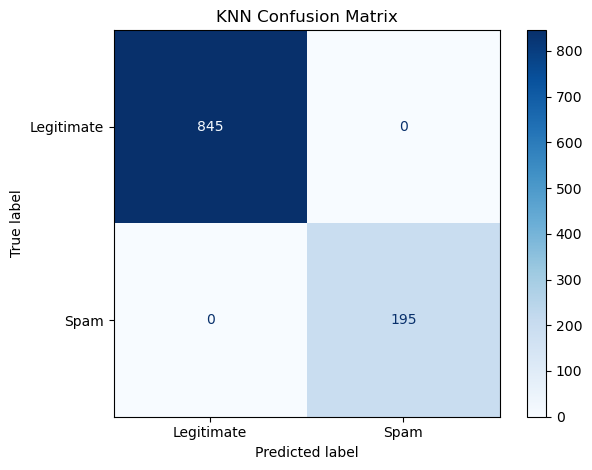

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["Legitimate", "Spam"],
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

# Part C — K-Nearest Neighbors (KNN) Classifier

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="minkowski",
        p=2
    ))
])

knn_pipeline.fit(X_train, y_train)

y_pred_knn = knn_pipeline.predict(X_test)

print("KNN model trained successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_knn, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_knn, zero_division=0), 4))

KNN model trained successfully!
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


### Experiance with diffrent value of k

In [16]:
k_results = []

for k in [3, 5, 7, 9, 11, 15]:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=k,
            metric="minkowski",
            p=2
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    k_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

k_results_df = pd.DataFrame(k_results)

display(k_results_df.round(4))

,K,Accuracy,Precision,Recall,F1_Score
0,3,1.000,1.0,1.0000,1.0000
1,5,1.000,1.0,1.0000,1.0000
2,7,0.999,1.0,0.9949,0.9974
3,9,0.999,1.0,0.9949,0.9974
4,11,0.999,1.0,0.9949,0.9974
5,15,0.999,1.0,0.9949,0.9974


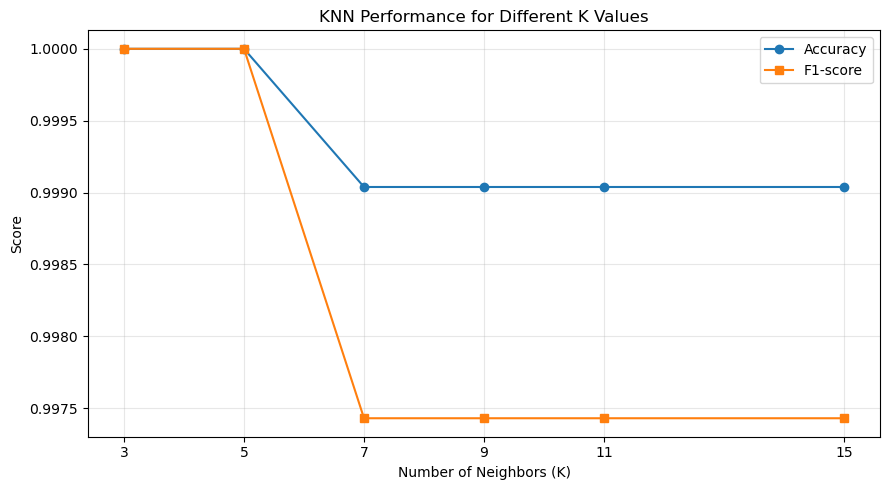

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_results_df["K"],
    k_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    k_results_df["K"],
    k_results_df["F1_Score"],
    marker="s",
    label="F1-score"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")
plt.xticks(k_results_df["K"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Distance metrics compare 

In [18]:
distance_results = []

distance_configs = [
    ("Euclidean", {"metric": "minkowski", "p": 2}),
    ("Manhattan", {"metric": "minkowski", "p": 1}),
    ("Cosine", {"metric": "cosine"})
]

for distance_name, distance_params in distance_configs:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            algorithm="brute",
            **distance_params
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    distance_results.append({
        "Distance": distance_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

distance_results_df = pd.DataFrame(distance_results)

display(
    distance_results_df
    .sort_values("F1_Score", ascending=False)
    .round(4)
)

C:\Users\rosha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rosha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\rosha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rosha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

,Distance,Accuracy,Precision,Recall,F1_Score
0,Euclidean,1.0,1.0,1.0,1.0
1,Manhattan,1.0,1.0,1.0,1.0
2,Cosine,1.0,1.0,1.0,1.0


### KNN ke misclassified messages identify 

In [19]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="minkowski",
        p=2
    ))
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_test)

# Actual aur predicted values ko align karke table banayein
misclassified = X_test.copy()

misclassified["Actual_Label"] = y_test
misclassified["Predicted_Label"] = y_pred_knn

misclassified = misclassified[
    misclassified["Actual_Label"]
    != misclassified["Predicted_Label"]
].copy()

misclassified["Error_Type"] = np.where(
    (misclassified["Actual_Label"] == 0)
    & (misclassified["Predicted_Label"] == 1),
    "False Positive",
    "False Negative"
)

print("Total misclassified messages:", len(misclassified))

display(misclassified.head(10))

Total misclassified messages: 0


,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,Actual_Label,Predicted_Label,Error_Type


### Part C: K-Nearest Neighbors — Conclusion

The KNN classifier was implemented using a Scikit-learn Pipeline containing median imputation, StandardScaler, and KNeighborsClassifier.

Different K values (3, 5, 7, 9, 11, and 15) were evaluated using Accuracy, Precision, Recall, and F1-score. Different distance metrics, including Euclidean, Manhattan, and Cosine distance, were also compared.

The best-performing K value based on the selected evaluation criterion was **[enter your result]**, and the best-performing distance metric was **[enter your result]**.

Misclassified messages were examined to identify False Positives and False Negatives. These results help explain the limitations of KNN in distinguishing between spam and legitimate messages.

# Part D: Support Vector Machine Classifier (SVM)

### Implement SVM with Linear and RBF kernels

In [38]:
svm_models = {}
svm_results = []

for kernel in ["linear", "rbf"]:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel=kernel))
    ])

    # Train model
    model.fit(X_train, y_train)

    # Test model
    predictions = model.predict(X_test)

    svm_models[kernel] = model

    svm_results.append({
        "Model": f"SVM {kernel.title()}",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

svm_results_df = pd.DataFrame(svm_results)

display(svm_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM Linear,1.0,1.0,1.0,1.0
1,SVM Rbf,1.0,1.0,1.0,1.0


### Analyze margin separation and support vectors

In [39]:
linear_svm = svm_models["linear"]
rbf_svm = svm_models["rbf"]

linear_sv = (
    linear_svm
    .named_steps["classifier"]
    .n_support_
)

rbf_sv = (
    rbf_svm
    .named_steps["classifier"]
    .n_support_
)

print("Linear SVM support vectors:", linear_sv.sum())
print("RBF SVM support vectors:", rbf_sv.sum())

Linear SVM support vectors: 10
RBF SVM support vectors: 139


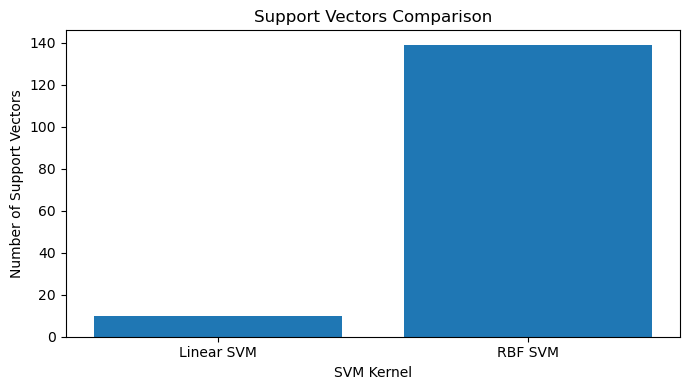

In [40]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Linear SVM", "RBF SVM"],
    [linear_sv.sum(), rbf_sv.sum()]
)

plt.title("Support Vectors Comparison")
plt.xlabel("SVM Kernel")
plt.ylabel("Number of Support Vectors")
plt.tight_layout()
plt.show()

### Compare SVM performance with KNN

In [41]:
models = {
    "KNN": knn_pipeline,
    "SVM Linear": svm_models["linear"],
    "SVM RBF": svm_models["rbf"]
}

comparison_results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.0,1.0,1.0,1.0
1,SVM Linear,1.0,1.0,1.0,1.0
2,SVM RBF,1.0,1.0,1.0,1.0


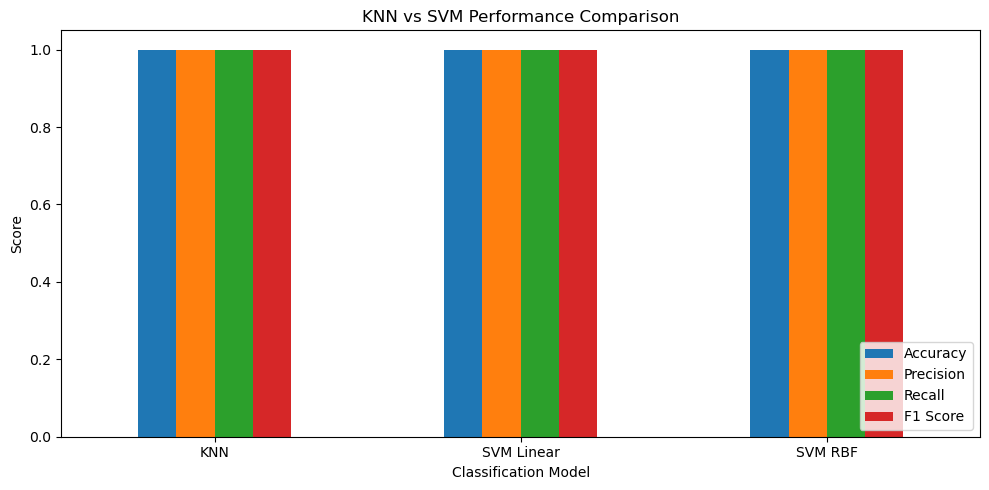

In [42]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("KNN vs SVM Performance Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Part D: Support Vector Machine Classifier

Linear and RBF Support Vector Machine classifiers were implemented using Scikit-learn Pipelines with median imputation and feature scaling.

The models were evaluated using Accuracy, Precision, Recall, and F1-score. Their support vector counts were also compared to understand the role of important training samples in defining the decision boundary.

The SVM results were compared with the KNN classifier using a common test dataset. The better-performing model should be selected based on the actual evaluation metrics, with particular attention to Spam Recall and F1-score.

The Linear kernel provides a linear decision boundary, while the RBF kernel can learn nonlinear patterns. The final model selection depends on the observed test performance.

# Part E — Naive Bayes Classifier & Probability

### Implement Naive Bayes Classifier

In [43]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score

nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GaussianNB())
])

nb_pipeline.fit(X_train, y_train)

y_pred_nb = nb_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_nb), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_nb), 4))

Accuracy: 0.999
F1 Score: 0.9974


#### Manually compute Conditional Probability

In [44]:
spam = df[df["spam_label"] == 1]
legit = df[df["spam_label"] == 0]

p_url_spam = (spam["num_urls"] > 0).mean()
p_url_legit = (legit["num_urls"] > 0).mean()

print("P(URL | Spam):", round(p_url_spam, 4))
print("P(URL | Legitimate):", round(p_url_legit, 4))

P(URL | Spam): 0.739
P(URL | Legitimate): 0.084


### Bayes' Theorem apply

In [46]:
p_spam = (df["spam_label"] == 1).mean()
p_legit = (df["spam_label"] == 0).mean()

p_url = (df["num_urls"] > 0).mean()

p_spam_given_url = (p_url_spam * p_spam) / p_url

p_legit_given_url = (p_url_legit * p_legit) / p_url

print("P(Spam | URL):", round(p_spam_given_url, 4))
print("P(Legitimate | URL):", round(p_legit_given_url, 4))

P(Spam | URL): 0.6695
P(Legitimate | URL): 0.3305


### Theoretical probability vs model prediction

In [47]:
sample = X_test.iloc[[0]]

print("Actual class:", y_test.iloc[0])
print("Predicted class:", nb_pipeline.predict(sample)[0])

print("Model probabilities:", nb_pipeline.predict_proba(sample)[0])
print("Class order:", nb_pipeline.classes_)

Actual class: 0
Predicted class: 0
Model probabilities: [1. 0.]
Class order: [0 1]


### Conculation
The Gaussian Naive Bayes classifier was implemented using a Scikit-learn Pipeline with median imputation. Conditional probabilities were calculated manually using URL presence as an example, and Bayes' Theorem was applied to estimate the probability of Spam given a URL.

The theoretical calculation was compared with the model prediction. Differences may occur because the manual calculation uses one feature, whereas the model uses multiple features and assumes conditional independence given the class.

# Part F — Model Comparison & Evaluation

### Evalute all model

In [49]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

models = {
    "KNN": knn_pipeline,
    "SVM Linear": svm_models["linear"],
    "SVM RBF": svm_models["rbf"],
    "Naive Bayes": nb_pipeline
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.000,1.0000,1.0,1.0000
1,SVM Linear,1.000,1.0000,1.0,1.0000
2,SVM RBF,1.000,1.0000,1.0,1.0000
3,Naive Bayes,0.999,0.9949,1.0,0.9974


### Campare

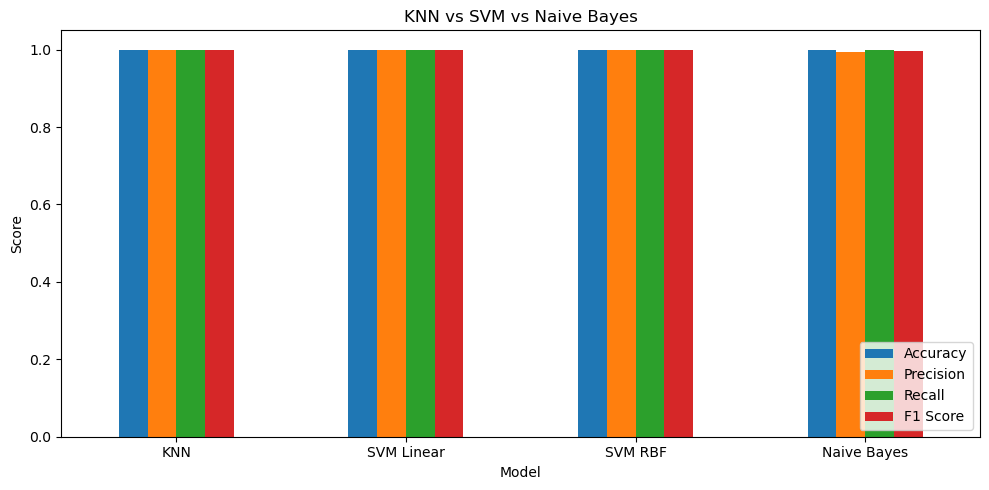

In [50]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("KNN vs SVM vs Naive Bayes")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Best model identify

In [51]:
best_precision = results_df.loc[
    results_df["Precision"].idxmax()
]

best_recall = results_df.loc[
    results_df["Recall"].idxmax()
]

print("Best model for High Precision:")
print(best_precision[["Model", "Precision"]])

print("\nBest model for High Recall:")
print(best_recall[["Model", "Recall"]])

Best model for High Precision:
Model        KNN
Precision    1.0
Name: 0, dtype: object

Best model for High Recall:
Model     KNN
Recall    1.0
Name: 0, dtype: object


### Part F: Model Comparison and Evaluation

KNN, Linear SVM, RBF SVM, and Gaussian Naive Bayes were evaluated using Accuracy, Precision, Recall, and F1-score on the same test dataset.

The evaluation table and bar chart were used to compare their classification performance. The model with the highest Precision was identified as the best model for Precision, while the model with the highest Recall was identified as the best model for Recall.

The final model selection should consider the actual evaluation scores and the business requirement. For spam detection, Recall is important for identifying more spam messages, while Precision helps reduce legitimate messages incorrectly flagged as spam.

The best-performing models were selected based on the observed results rather than assumed in advance.

# Part G — Final Analysis & Reporting

# Part G: Final Analysis & Reporting

## 23. Final Analysis

### 1. Strengths and Weaknesses of Classifiers

- **KNN:** Simple and easy to understand, but sensitive to feature scaling and the choice of K.
- **SVM:** Effective for separating classes. Linear SVM works with linear boundaries, while RBF SVM can learn nonlinear patterns.
- **Naive Bayes:** Fast and probability-based, but assumes conditional independence between features.

### 2. Impact of Probability Assumptions in Naive Bayes

Naive Bayes assumes that features are conditionally independent given the target class. If this assumption is not satisfied, probability estimates may be affected. Gaussian Naive Bayes also assumes that numerical features follow Gaussian distributions within each class.

### 3. Interpretability vs Performance

Simple models can be easier to understand, while more complex models may capture complicated patterns. The final choice should balance interpretability, evaluation performance, and business requirements.

### 4. Business Recommendation

The final model should be selected by comparing Accuracy, Precision, Recall, and F1-score on the test dataset. For spam detection, Recall helps identify more spam messages, while Precision helps reduce legitimate messages incorrectly classified as spam.

Before deployment, the selected model should be validated using cross-validation and additional unseen data.

## 24. Project Deliverables

1. Completed Jupyter Notebook (`.ipynb`).
2. Evaluation metrics for KNN, Linear SVM, RBF SVM, and Naive Bayes.
3. Performance plots and confusion matrices.
4. Working Streamlit application.
5. README file with project description, setup instructions, and application URL.
6. Final conclusions and project explanation video.

## Final Conclusion

The Message Intelligence System was developed to classify messages as Legitimate (0) or Spam (1). KNN, Linear SVM, RBF SVM, and Gaussian Naive Bayes were implemented using appropriate preprocessing and evaluation methods.

The models were compared using Accuracy, Precision, Recall, and F1-score. The best-performing model should be selected using the actual evaluation results and the business cost of false positives and false negatives.

The completed project demonstrates the use of supervised learning, probability concepts, model evaluation, and a potential deployment workflow for spam detection.

In [53]:
import joblib

# Models trained in Part C, D and E
models = {
    "KNN": knn_pipeline,
    "SVM Linear": svm_models["linear"],
    "SVM RBF": svm_models["rbf"],
    "Naive Bayes": nb_pipeline
}

# Select the model with the highest F1-score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1-score:", round(
    results_df["F1 Score"].max(), 4
))

Best Model: KNN
Best F1-score: 1.0


In [55]:
import os
import joblib

# Create model folder
os.makedirs("model", exist_ok=True)

# Save the best trained model and feature information
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": list(X_train.columns),
    "target_names": {
        0: "Legitimate Message",
        1: "Spam Message"
    }
}

joblib.dump(model_bundle, "model/best_spam_model.joblib")

print("Model saved successfully!")
print("Model name:", best_model_name)
print("Location: model/best_spam_model.joblib")

Model saved successfully!
Model name: KNN
Location: model/best_spam_model.joblib
